## Detection des fraudes par carte de credit

### Étape 1.1 : Charger les données
### On utilise un dataset comme celui de Kaggle. Assure-toi de télécharger le fichier creditcard.csv

In [2]:
import pandas as pd
import numpy as np

# Charger le dataset
file_path = "creditcard.csv"  # Remplace par le chemin de ton fichier
data = pd.read_csv(file_path)

# Aperçu des données
print(data.head())
print(data.info())


   Time        V1        V2        V3        V4        V5        V6        V7  \
0   0.0 -1.359807 -0.072781  2.536347  1.378155 -0.338321  0.462388  0.239599   
1   0.0  1.191857  0.266151  0.166480  0.448154  0.060018 -0.082361 -0.078803   
2   1.0 -1.358354 -1.340163  1.773209  0.379780 -0.503198  1.800499  0.791461   
3   1.0 -0.966272 -0.185226  1.792993 -0.863291 -0.010309  1.247203  0.237609   
4   2.0 -1.158233  0.877737  1.548718  0.403034 -0.407193  0.095921  0.592941   

         V8        V9  ...       V21       V22       V23       V24       V25  \
0  0.098698  0.363787  ... -0.018307  0.277838 -0.110474  0.066928  0.128539   
1  0.085102 -0.255425  ... -0.225775 -0.638672  0.101288 -0.339846  0.167170   
2  0.247676 -1.514654  ...  0.247998  0.771679  0.909412 -0.689281 -0.327642   
3  0.377436 -1.387024  ... -0.108300  0.005274 -0.190321 -1.175575  0.647376   
4 -0.270533  0.817739  ... -0.009431  0.798278 -0.137458  0.141267 -0.206010   

        V26       V27       V28 

### Étape 1.2 : Analyse exploratoire (EDA)
### Ici, on visualise la distribution des classes et la corrélation des variables.

Distribution des classes :
 Class
0    284315
1       492
Name: count, dtype: int64


C:\Users\user\AppData\Local\Temp\ipykernel_26380\3936045633.py:10: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=class_counts.index, y=class_counts.values, palette="viridis")


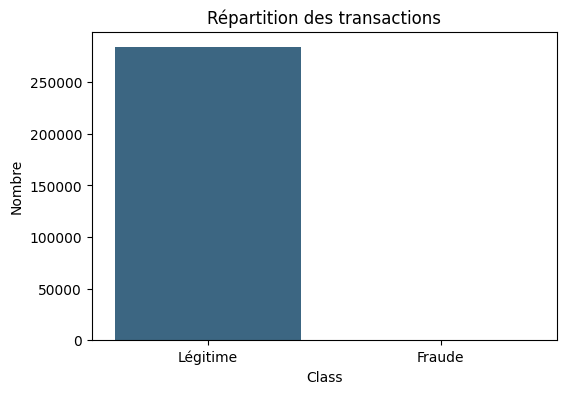

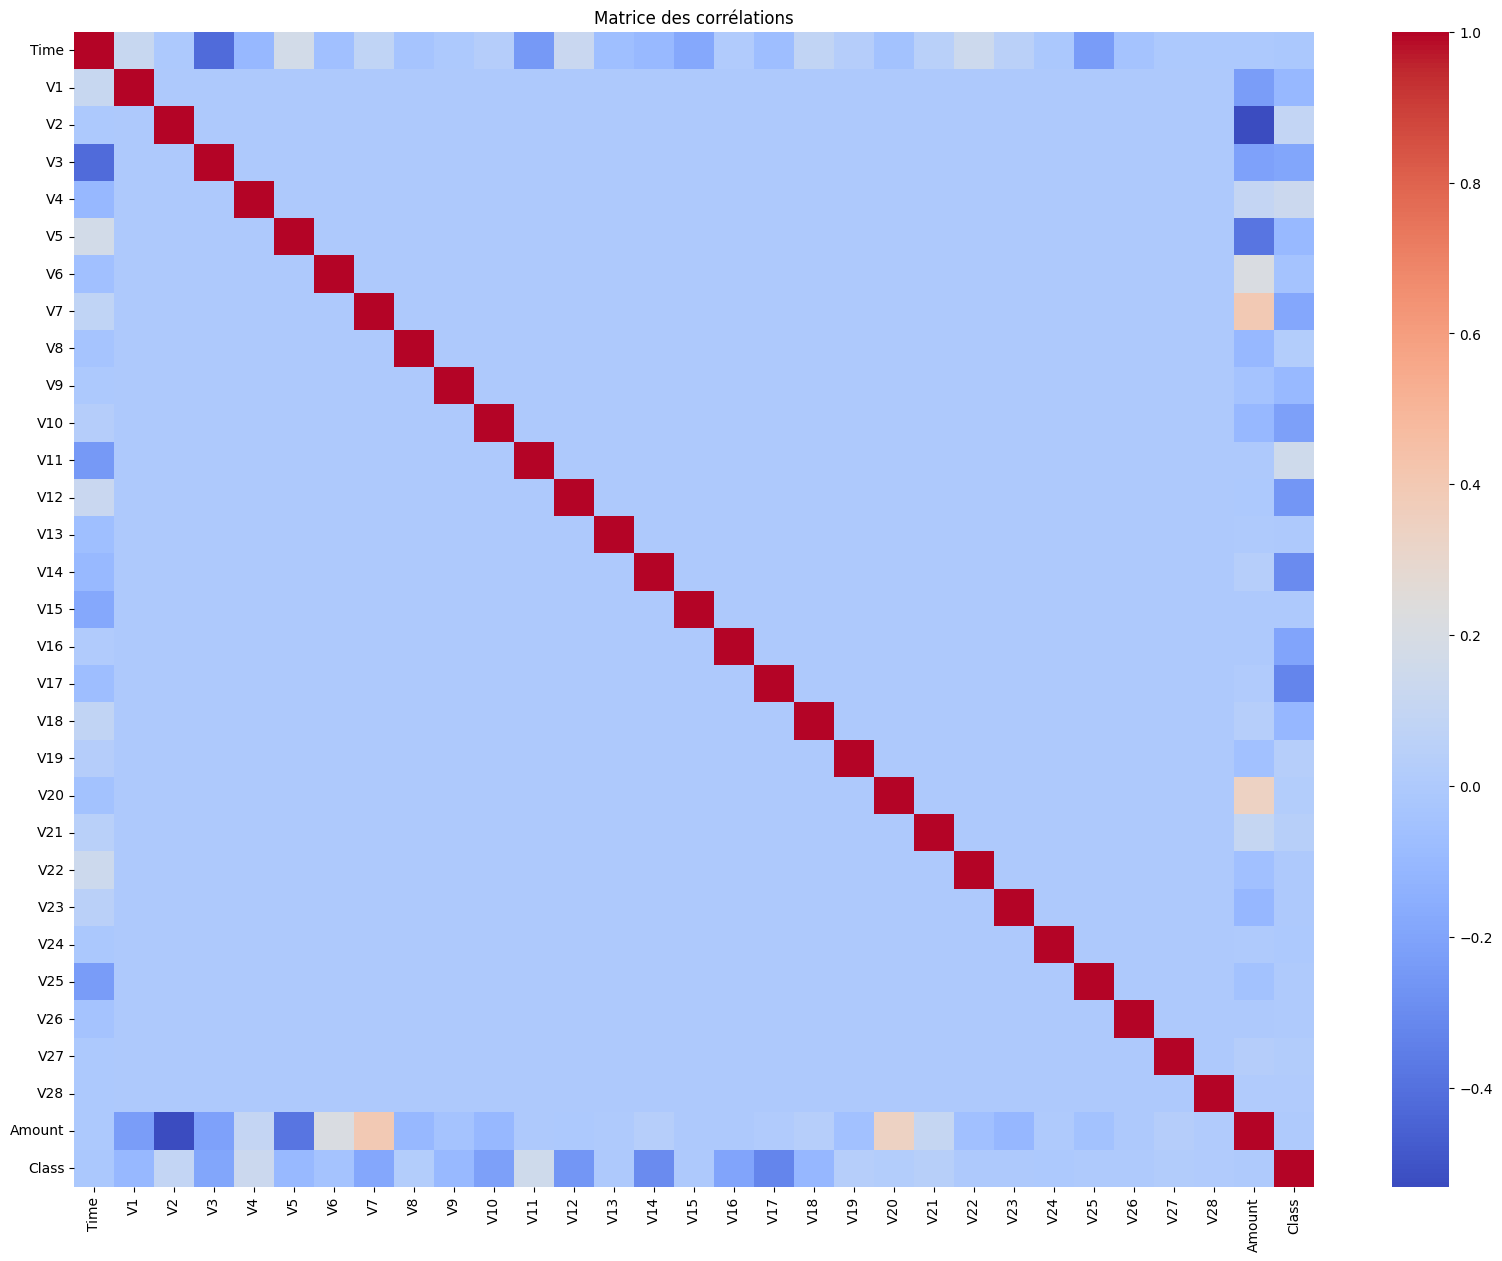

In [3]:
import matplotlib.pyplot as plt
import seaborn as sns

# Distribution des classes (0 = légitime, 1 = frauduleux)
class_counts = data['Class'].value_counts()
print("Distribution des classes :\n", class_counts)

# Visualiser la répartition
plt.figure(figsize=(6, 4))
sns.barplot(x=class_counts.index, y=class_counts.values, palette="viridis")
plt.title("Répartition des transactions")
plt.xticks([0, 1], ['Légitime', 'Fraude'])
plt.ylabel("Nombre")
plt.show()

# Heatmap des corrélations
corr_matrix = data.corr()
plt.figure(figsize=(20, 15))
sns.heatmap(corr_matrix, cmap='coolwarm', annot=False)
plt.title("Matrice des corrélations")
plt.show()


### 2. Traitement des données
### Étape 2.1 : Équilibrage des classes avec SMOTE
### Les transactions frauduleuses étant rares, nous utilisons SMOTE pour équilibrer les classes.

In [5]:
from imblearn.over_sampling import SMOTE
from sklearn.model_selection import train_test_split

# Séparer les caractéristiques et les étiquettes
X = data.drop('Class', axis=1)
y = data['Class']

# Diviser en jeu d'entraînement et de test
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

# Appliquer SMOTE
smote = SMOTE(random_state=42)
X_train_smote, y_train_smote = smote.fit_resample(X_train, y_train)

print("Avant SMOTE :", y_train.value_counts())
print("Après SMOTE :", pd.Series(y_train_smote).value_counts())


Avant SMOTE : Class
0    227451
1       394
Name: count, dtype: int64
Après SMOTE : Class
0    227451
1    227451
Name: count, dtype: int64


### Étape 2.2 : Normalisation des données
### La normalisation permet de mieux gérer les données ayant des échelles différentes.

In [6]:
from sklearn.preprocessing import StandardScaler

# Normaliser les données
scaler = StandardScaler()
X_train_smote = scaler.fit_transform(X_train_smote)
X_test = scaler.transform(X_test)


3. Création et évaluation des modèles
### Étape 3.1 : Entraîner un modèle
### On utilise un Random Forest comme exemple.

In [7]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score

# Entraîner le modèle
model = RandomForestClassifier(random_state=42)
model.fit(X_train_smote, y_train_smote)

# Prédictions
y_pred = model.predict(X_test)
y_proba = model.predict_proba(X_test)[:, 1]

# Évaluation des performances
print("Classification Report:\n", classification_report(y_test, y_pred))
print("ROC-AUC Score:", roc_auc_score(y_test, y_proba))


Classification Report:
               precision    recall  f1-score   support

           0       1.00      1.00      1.00     56864
           1       0.84      0.83      0.83        98

    accuracy                           1.00     56962
   macro avg       0.92      0.91      0.92     56962
weighted avg       1.00      1.00      1.00     56962

ROC-AUC Score: 0.9644220941049464


### Étape 3.2 : Visualiser les résultats
### Une matrice de confusion et une courbe ROC permettent d’évaluer le modèle.

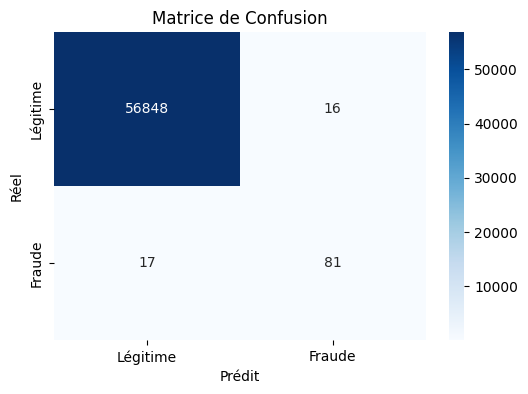

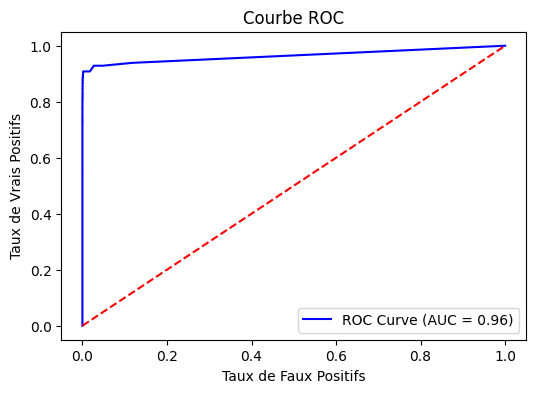

In [8]:
from sklearn.metrics import roc_curve, auc

# Matrice de confusion
conf_matrix = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(6, 4))
sns.heatmap(conf_matrix, annot=True, fmt='d', cmap='Blues', xticklabels=['Légitime', 'Fraude'], yticklabels=['Légitime', 'Fraude'])
plt.title("Matrice de Confusion")
plt.ylabel("Réel")
plt.xlabel("Prédit")
plt.show()

# Courbe ROC
fpr, tpr, thresholds = roc_curve(y_test, y_proba)
roc_auc = auc(fpr, tpr)

plt.figure(figsize=(6, 4))
plt.plot(fpr, tpr, color='blue', label=f"ROC Curve (AUC = {roc_auc:.2f})")
plt.plot([0, 1], [0, 1], color='red', linestyle='--')
plt.title("Courbe ROC")
plt.xlabel("Taux de Faux Positifs")
plt.ylabel("Taux de Vrais Positifs")
plt.legend()
plt.show()


4. Création d’un Dashboard interactif
### On peut utiliser Streamlit pour rendre ce projet interactif. Voici un exemple de script :

In [15]:
import streamlit as st

# Titre
st.title("Détection de Fraudes Bancaires")

# Charger les données
st.write("### Aperçu des données")
st.dataframe(data.head())

# Visualisation des résultats
st.write("### Matrice de Confusion")
st.image("confusion_matrix.png")  # Ajouter une image générée précédemment
st.write("### Courbe ROC")
st.image("roc_curve.png")


2025-01-10 09:31:10.605 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2025-01-10 09:31:10.617 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2025-01-10 09:31:10.622 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2025-01-10 09:31:10.623 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2025-01-10 09:31:10.625 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2025-01-10 09:31:10.627 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2025-01-10 09:31:10.777 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2025-01-10 09:31:10.778 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bar

DeltaGenerator()